# Environmental and Vector Analysis Pipeline
## Correlation between climate and *An. gambiae* abundance in Selected Country/Region

### 1. Setup and Imports

In [4]:
import sys
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sqlalchemy import text
import geopandas as gpd
from shapely import wkt
import contextily as ctx
import warnings
warnings.filterwarnings('ignore')

# Add project root to path
project_root = Path.cwd().parent
sys.path.append(str(project_root))

from database.session import engine
from database.models import Location, VectorObservation, EnvironmentalFactor

# Set plotting style
plt.style.use('seaborn-v0_8-darkgrid')
sns.set_palette("husl")

### 2. Configuration - Set Analysis Parameters

In [5]:
# ===== CONFIGURATION =====
# Set the country and region you want to analyze

# Option 1: Filter by country (all regions within country)
COUNTRY_NAME = "Ghana"  # e.g., "Ghana", "Kenya"
COUNTRY_CODE = "GH"     # ISO country code (e.g., "GH", "KE")

# Option 2: Optionally filter by specific region name within the country
# Set to None to include all regions in the country
REGION_NAME = "Greater Accra"  # e.g., "Greater Accra", "Siaya", or None for all

# Species filter
SPECIES_FILTER = '%gambiae%'  # SQL LIKE pattern for species

# Date range (optional - set to None for all dates)
START_DATE = None  # e.g., '2024-01-01'
END_DATE = None    # e.g., '2025-12-31'

print(f"Analysis Configuration:")
print(f"- Country: {COUNTRY_NAME} ({COUNTRY_CODE})")
print(f"- Region: {REGION_NAME if REGION_NAME else 'All regions'}")
print(f"- Species: {SPECIES_FILTER}")
print(f"- Date range: {START_DATE if START_DATE else 'All dates'} to {END_DATE if END_DATE else 'All dates'}")

Analysis Configuration:
- Country: Ghana (GH)
- Region: Greater Accra
- Species: %gambiae%
- Date range: All dates to All dates


### 3. Data Loading and Preprocessing

In [6]:
def load_country_locations(country_name, country_code, region_name=None):
    """Load location data for a specific country and optional region."""
    
    query = """
    SELECT 
        location_code,
        name,
        admin_level,
        geometry_wkt,
        centroid_lat,
        centroid_lon,
        country_name,
        country_code
    FROM location
    WHERE country_name = :country_name 
       OR country_code = :country_code
    """
    
    params = {'country_name': country_name, 'country_code': country_code}
    
    if region_name:
        query += " AND name = :region_name"
        params['region_name'] = region_name
    
    df_locations = pd.read_sql(text(query), engine, params=params)
    
    print(f"Found {len(df_locations)} locations in {country_name}")
    
    # Convert to GeoDataFrame for locations with geometry
    gdf_locations = None
    if len(df_locations) > 0 and 'geometry_wkt' in df_locations.columns:
        # Filter out rows without geometry
        df_with_geom = df_locations[df_locations['geometry_wkt'].notna()].copy()
        if len(df_with_geom) > 0:
            df_with_geom['geometry'] = df_with_geom['geometry_wkt'].apply(wkt.loads)
            gdf_locations = gpd.GeoDataFrame(df_with_geom, crs='EPSG:4326')
    
    return df_locations, gdf_locations


def load_vector_data(location_codes, species_filter='%gambiae%', start_date=None, end_date=None):
    """Load vector observation data for specified location codes."""
    
    if not location_codes:
        print("No location codes provided")
        return pd.DataFrame(), None
    
    # Create placeholders for SQL IN clause
    placeholders = ','.join([f':code_{i}' for i in range(len(location_codes))])
    params = {f'code_{i}': code for i, code in enumerate(location_codes)}
    params['species'] = species_filter
    
    query = f"""
    SELECT 
        v.date_id,
        v.location_code,
        v.vector_species,
        v.count,
        l.centroid_lat AS lat,
        l.centroid_lon AS lon,
        l.geometry_wkt AS geom_wkt,
        l.name AS location_name,
        l.admin_level,
        l.country_name,
        l.country_code
    FROM vector_observation v
    JOIN location l ON v.location_code = l.location_code
    WHERE v.vector_species LIKE :species
      AND v.location_code IN ({placeholders})
    """
    
    if start_date:
        query += " AND v.date_id >= :start_date"
        params['start_date'] = start_date
    
    if end_date:
        query += " AND v.date_id <= :end_date"
        params['end_date'] = end_date
    
    query += " ORDER BY v.date_id"
    
    df_vec = pd.read_sql(text(query), engine, params=params)
    print(f"Total vector observations: {len(df_vec)}")
    
    # Convert to GeoDataFrame if we have coordinates
    gdf_points = None
    if len(df_vec) > 0:
        df_with_coords = df_vec[df_vec['lat'].notna() & df_vec['lon'].notna()].copy()
        if len(df_with_coords) > 0:
            gdf_points = gpd.GeoDataFrame(
                df_with_coords,
                geometry=gpd.points_from_xy(df_with_coords['lon'], df_with_coords['lat']),
                crs='EPSG:4326'
            )
    
    return df_vec, gdf_points


def load_environmental_data(location_codes, start_date=None, end_date=None):
    """Load environmental data for specified location codes."""
    
    if not location_codes:
        print("No location codes provided")
        return pd.DataFrame()
    
    # Create placeholders for SQL IN clause
    placeholders = ','.join([f':code_{i}' for i in range(len(location_codes))])
    params = {f'code_{i}': code for i, code in enumerate(location_codes)}
    
    query = f"""
    SELECT 
        e.date_id,
        e.location_code,
        e.temperature_mean,
        e.rainfall_total,
        l.name AS location_name,
        l.country_name,
        l.country_code
    FROM environmental_factor e
    JOIN location l ON e.location_code = l.location_code
    WHERE e.location_code IN ({placeholders})
    """
    
    if start_date:
        query += " AND e.date_id >= :start_date"
        params['start_date'] = start_date
    
    if end_date:
        query += " AND e.date_id <= :end_date"
        params['end_date'] = end_date
    
    query += " ORDER BY e.date_id"
    
    df_env = pd.read_sql(text(query), engine, params=params)
    df_env['date'] = pd.to_datetime(df_env['date_id'])
    print(f"Environmental records: {len(df_env)} days")
    
    return df_env


# Load data based on configuration
df_locations, gdf_locations = load_country_locations(COUNTRY_NAME, COUNTRY_CODE, REGION_NAME)

if len(df_locations) == 0:
    print(f"No locations found for {COUNTRY_NAME}. Please check country name/code.")
    # Show available countries as a hint
    countries_df = pd.read_sql("SELECT DISTINCT country_name, country_code FROM location WHERE country_name IS NOT NULL", engine)
    print("\nAvailable countries in database:")
    print(countries_df.to_string(index=False))
else:
    location_codes = df_locations['location_code'].tolist()
    
    # Load vector data
    df_vec, gdf_points = load_vector_data(location_codes, SPECIES_FILTER, START_DATE, END_DATE)
    
    # Load environmental data
    df_env = load_environmental_data(location_codes, START_DATE, END_DATE)

    # Display summary
    print(f"\nData Summary:")
    print(f"- Locations: {len(df_locations)}")
    print(f"- Vector observations: {len(df_vec)}")
    print(f"- Environmental records: {len(df_env)}")

Found 36 locations in Ghana
Total vector observations: 6308
Environmental records: 732 days

Data Summary:
- Locations: 36
- Vector observations: 6308
- Environmental records: 732


### 4. Optional: Create Region Boundary for Spatial Filtering

In [7]:
# If you want to further filter points within a specific region boundary
# (useful when you have point data across a country but want to focus on one region)

def get_region_boundary(region_name, country_name=None):
    """Get the boundary polygon for a specific region."""
    query = """
    SELECT geometry_wkt, name, admin_level
    FROM location
    WHERE name = :region_name
    """
    params = {'region_name': region_name}
    
    if country_name:
        query += " AND (country_name = :country_name OR country_code = :country_code)"
        params['country_name'] = country_name
        params['country_code'] = COUNTRY_CODE
    
    result = pd.read_sql(text(query), engine, params=params)
    
    if len(result) == 0:
        print(f"No boundary found for region: {region_name}")
        return None
    
    boundary = wkt.loads(result.iloc[0]['geometry_wkt'])
    gdf_boundary = gpd.GeoDataFrame({'geometry': [boundary]}, crs='EPSG:4326')
    
    print(f"Found boundary for {region_name} (admin_level: {result.iloc[0]['admin_level']})")
    return gdf_boundary


# Apply spatial filter if region boundary is available
gdf_filtered_points = gdf_points.copy() if gdf_points is not None else None

if REGION_NAME and gdf_points is not None:
    region_boundary = get_region_boundary(REGION_NAME, COUNTRY_NAME)
    if region_boundary is not None:
        gdf_filtered_points = gdf_points[gdf_points.within(region_boundary.unary_union)]
        print(f"Points within {REGION_NAME}: {len(gdf_filtered_points)} (out of {len(gdf_points)} total)")
    else:
        print(f"No boundary found for {REGION_NAME}. Using all points in {COUNTRY_NAME}.")
        gdf_filtered_points = gdf_points
else:
    if gdf_points is not None:
        print(f"Using all {len(gdf_points)} points in {COUNTRY_NAME}")
        gdf_filtered_points = gdf_points

Found boundary for Greater Accra (admin_level: region)
Points within Greater Accra: 6156 (out of 6308 total)


### 5. Temporal Aggregation and Analysis

In [8]:
def aggregate_to_monthly(gdf_points, df_env):
    """Aggregate vector and environmental data to monthly resolution."""
    
    if gdf_points is None or len(gdf_points) == 0:
        print("No vector points to aggregate")
        return pd.DataFrame()
    
    # Vector monthly aggregation
    df_vec_monthly = gdf_points.groupby('date_id')['count'].agg(['sum', 'mean', 'std']).reset_index()
    df_vec_monthly.columns = ['date_id', 'total_count', 'mean_count', 'std_count']
    df_vec_monthly['date'] = pd.to_datetime(df_vec_monthly['date_id'])
    
    print(f"Monthly vector observations: {len(df_vec_monthly)} months")
    print("Vector date range:", df_vec_monthly['date_id'].min(), "to", df_vec_monthly['date_id'].max())
    
    if len(df_env) == 0:
        print("No environmental data to aggregate")
        return df_vec_monthly
    
    # Environmental monthly aggregation
    numeric_cols = ['temperature_mean', 'rainfall_total']
    
    # Create a copy and set index properly
    df_env_indexed = df_env.set_index('date').copy()
    
    # Resample and aggregate
    df_env_monthly = df_env_indexed[numeric_cols].resample('ME').agg(['mean', 'std', 'min', 'max'])
    
    # Flatten column names
    df_env_monthly.columns = ['_'.join(col).strip() for col in df_env_monthly.columns.values]
    df_env_monthly = df_env_monthly.reset_index()
    df_env_monthly['date_id'] = df_env_monthly['date'].dt.strftime('%Y-%m-01')
    
    print(f"Monthly environmental records: {len(df_env_monthly)} months")
    print("Environmental date range:", df_env_monthly['date_id'].min(), "to", df_env_monthly['date_id'].max())
    
    # Merge datasets
    df_merged = pd.merge(
        df_vec_monthly,
        df_env_monthly,
        on='date_id',
        how='inner'
    )
    
    # Ensure date column exists
    if 'date' not in df_merged.columns:
        df_merged['date'] = pd.to_datetime(df_merged['date_id'])
    
    print(f"Overlapping months: {len(df_merged)}")
    return df_merged


if gdf_filtered_points is not None and len(gdf_filtered_points) > 0:
    df_merged = aggregate_to_monthly(gdf_filtered_points, df_env)
else:
    print("No data to analyze")
    df_merged = pd.DataFrame()

Monthly vector observations: 3 months
Vector date range: 2023-01-01 to 2025-01-01
Monthly environmental records: 25 months
Environmental date range: 2023-12-01 to 2025-12-01
Overlapping months: 2


### 6. Exploratory Data Analysis

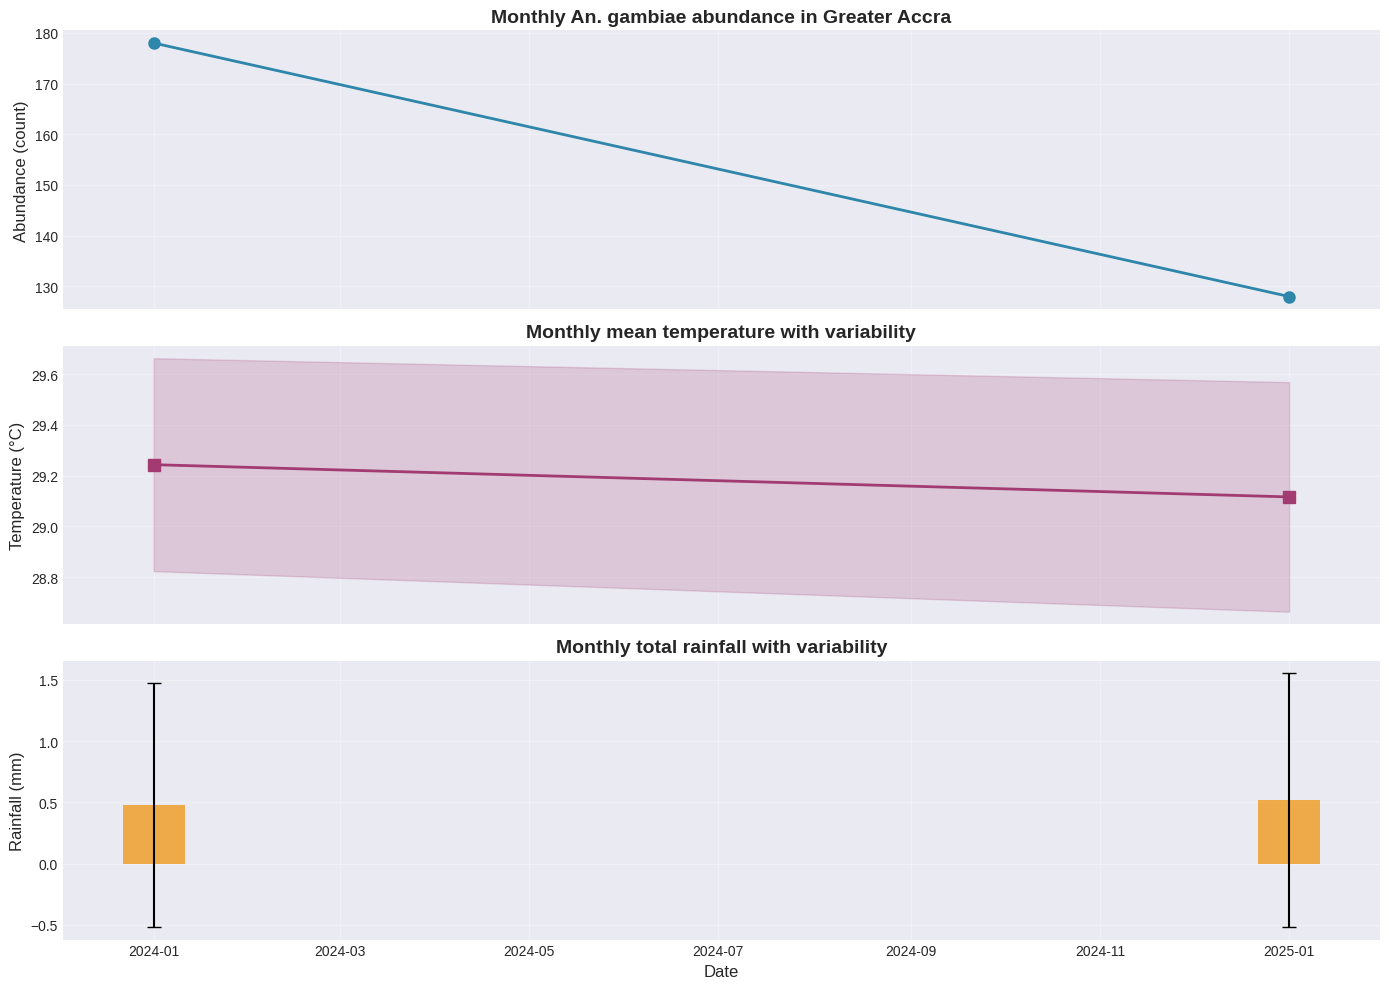

In [9]:
def plot_time_series(df_merged, region_name):
    """Create comprehensive time series visualization."""
    
    if df_merged.empty:
        print("No data to plot")
        return
    
    fig, axes = plt.subplots(3, 1, figsize=(14, 10), sharex=True)
    
    region_title = region_name if region_name else COUNTRY_NAME
    
    # Abundance
    axes[0].plot(df_merged['date'], df_merged['total_count'], 
                 marker='o', linestyle='-', linewidth=2, markersize=8, color='#2E86AB')
    if 'std_count' in df_merged.columns:
        axes[0].fill_between(df_merged['date'], 
                              df_merged['total_count'] - df_merged['std_count'],
                              df_merged['total_count'] + df_merged['std_count'],
                              alpha=0.2, color='#2E86AB')
    axes[0].set_ylabel('Abundance (count)', fontsize=12)
    axes[0].set_title(f'Monthly An. gambiae abundance in {region_title}', fontsize=14, fontweight='bold')
    axes[0].grid(True, alpha=0.3)
    
    # Temperature
    if 'temperature_mean_mean' in df_merged.columns:
        axes[1].plot(df_merged['date'], df_merged['temperature_mean_mean'], 
                     marker='s', linestyle='-', linewidth=2, markersize=8, color='#A23B72')
        if 'temperature_mean_std' in df_merged.columns:
            axes[1].fill_between(df_merged['date'],
                                  df_merged['temperature_mean_mean'] - df_merged['temperature_mean_std'],
                                  df_merged['temperature_mean_mean'] + df_merged['temperature_mean_std'],
                                  alpha=0.2, color='#A23B72')
        axes[1].set_ylabel('Temperature (°C)', fontsize=12)
        axes[1].set_title('Monthly mean temperature with variability', fontsize=14, fontweight='bold')
        axes[1].grid(True, alpha=0.3)
    else:
        axes[1].set_visible(False)
    
    # Rainfall
    if 'rainfall_total_mean' in df_merged.columns:
        axes[2].bar(df_merged['date'], df_merged['rainfall_total_mean'], 
                    width=20, color='#F18F01', alpha=0.7, label='Mean rainfall')
        if 'rainfall_total_std' in df_merged.columns:
            axes[2].errorbar(df_merged['date'], df_merged['rainfall_total_mean'],
                             yerr=df_merged['rainfall_total_std'],
                             fmt='none', color='black', capsize=5)
        axes[2].set_ylabel('Rainfall (mm)', fontsize=12)
        axes[2].set_title('Monthly total rainfall with variability', fontsize=14, fontweight='bold')
        axes[2].grid(True, alpha=0.3)
    else:
        axes[2].set_visible(False)
    
    plt.xlabel('Date', fontsize=12)
    plt.tight_layout()
    plt.show()


if not df_merged.empty:
    plot_time_series(df_merged, REGION_NAME)
else:
    print("No data available for time series plot")

### 7. Correlation Analysis

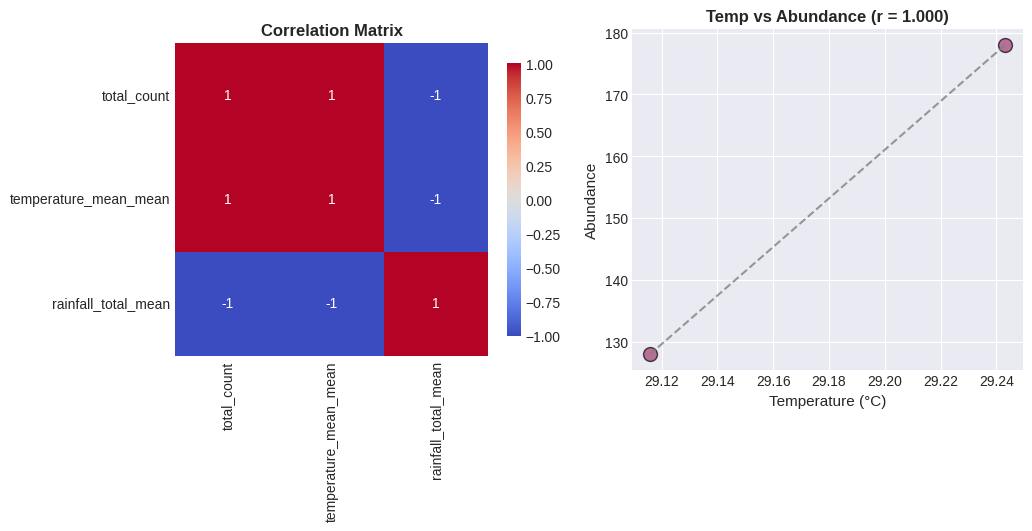

In [10]:
def analyze_correlations(df_merged):
    """Compute and visualize correlations between variables."""
    
    if df_merged.empty or len(df_merged) < 2:
        print("Insufficient data for correlation analysis")
        return None
    
    # Check which columns are available
    available_cols = ['total_count']
    if 'temperature_mean_mean' in df_merged.columns:
        available_cols.append('temperature_mean_mean')
    if 'rainfall_total_mean' in df_merged.columns:
        available_cols.append('rainfall_total_mean')
    
    if len(available_cols) < 2:
        print("Not enough variables for correlation analysis")
        return None
    
    # Basic correlations
    corr_matrix = df_merged[available_cols].corr()
    
    fig, axes = plt.subplots(1, 3, figsize=(15, 5))
    
    # Correlation matrix heatmap
    sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', center=0,
                square=True, ax=axes[0], cbar_kws={"shrink": 0.8})
    axes[0].set_title('Correlation Matrix', fontsize=12, fontweight='bold')
    
    plot_idx = 1
    
    # Temperature scatter
    if 'temperature_mean_mean' in df_merged.columns:
        axes[plot_idx].scatter(df_merged['temperature_mean_mean'], df_merged['total_count'], 
                               s=100, alpha=0.7, color='#A23B72', edgecolors='black')
        axes[plot_idx].set_xlabel('Temperature (°C)', fontsize=11)
        axes[plot_idx].set_ylabel('Abundance', fontsize=11)
        r_val = corr_matrix.loc['total_count', 'temperature_mean_mean']
        axes[plot_idx].set_title(f'Temp vs Abundance (r = {r_val:.3f})', 
                                  fontsize=12, fontweight='bold')
        
        # Add trend line
        z = np.polyfit(df_merged['temperature_mean_mean'], df_merged['total_count'], 1)
        p = np.poly1d(z)
        axes[plot_idx].plot(df_merged['temperature_mean_mean'], p(df_merged['temperature_mean_mean']), 
                            '--', color='gray', alpha=0.8)
        plot_idx += 1
    
    # Rainfall scatter
    if 'rainfall_total_mean' in df_merged.columns and plot_idx < 3:
        axes[plot_idx].scatter(df_merged['rainfall_total_mean'], df_merged['total_count'],
                               s=100, alpha=0.7, color='#F18F01', edgecolors='black')
        axes[plot_idx].set_xlabel('Rainfall (mm)', fontsize=11)
        axes[plot_idx].set_ylabel('Abundance', fontsize=11)
        r_val = corr_matrix.loc['total_count', 'rainfall_total_mean']
        axes[plot_idx].set_title(f'Rainfall vs Abundance (r = {r_val:.3f})',
                                  fontsize=12, fontweight='bold')
        
        # Add trend line
        z = np.polyfit(df_merged['rainfall_total_mean'], df_merged['total_count'], 1)
        p = np.poly1d(z)
        axes[plot_idx].plot(df_merged['rainfall_total_mean'], p(df_merged['rainfall_total_mean']),
                            '--', color='gray', alpha=0.8)
    
    # Hide any unused subplots
    for i in range(plot_idx, 3):
        axes[i].set_visible(False)
    
    plt.tight_layout()
    plt.show()
    
    return corr_matrix


if not df_merged.empty:
    corr_matrix = analyze_correlations(df_merged)
else:
    print("No data for correlation analysis")

### 8. Lagged Correlation Analysis

In [11]:
def analyze_lagged_correlations(df_merged, max_lag=3):
    """Analyze lagged correlations between climate variables and abundance."""
    
    if df_merged.empty or len(df_merged) < max_lag + 1:
        print(f"Insufficient data for lagged correlation analysis (need at least {max_lag + 1} months)")
        return {}
    
    # Determine which climate variables are available
    climate_vars = []
    if 'temperature_mean_mean' in df_merged.columns:
        climate_vars.append(('temperature_mean_mean', 'Temperature', '#A23B72'))
    if 'rainfall_total_mean' in df_merged.columns:
        climate_vars.append(('rainfall_total_mean', 'Rainfall', '#F18F01'))
    
    if not climate_vars:
        print("No climate variables available for lagged analysis")
        return {}
    
    n_rows = len(climate_vars)
    fig, axes = plt.subplots(n_rows, max_lag, figsize=(15, 5 * n_rows))
    
    # Handle single row case
    if n_rows == 1:
        axes = axes.reshape(1, -1)
    
    lags = range(1, max_lag + 1)
    lag_correlations = {}
    
    for row_idx, (var_name, var_label, color) in enumerate(climate_vars):
        var_corrs = []
        
        for i, lag in enumerate(lags):
            # Create lagged variable
            df_lag = df_merged[[var_name, 'total_count']].copy()
            df_lag[f'{var_name}_lag'] = df_lag[var_name].shift(lag)
            df_clean = df_lag.dropna()
            
            if len(df_clean) > 1:
                corr = df_clean[[f'{var_name}_lag', 'total_count']].corr().iloc[0, 1]
                var_corrs.append(corr)
                
                axes[row_idx, i].scatter(df_clean[f'{var_name}_lag'], df_clean['total_count'],
                                         alpha=0.7, s=80, color=color, edgecolors='black')
                axes[row_idx, i].set_xlabel(f'{var_label} (lag {lag} mo)', fontsize=10)
                axes[row_idx, i].set_ylabel('Abundance', fontsize=10)
                axes[row_idx, i].set_title(f'r = {corr:.3f}', fontsize=11, fontweight='bold')
                axes[row_idx, i].grid(True, alpha=0.3)
        
        lag_correlations[var_label.lower()] = var_corrs
    
    # Set row labels
    for row_idx, (_, var_label, _) in enumerate(climate_vars):
        axes[row_idx, 0].set_ylabel(f'Abundance\n({var_label} lag)', fontsize=11)
    
    plt.suptitle('Lagged Correlation Analysis', fontsize=14, fontweight='bold', y=1.02)
    plt.tight_layout()
    plt.show()
    
    return lag_correlations


if not df_merged.empty:
    lag_correlations = analyze_lagged_correlations(df_merged)
else:
    print("No data for lagged correlation analysis")

Insufficient data for lagged correlation analysis (need at least 4 months)


### 9. Spatial Distribution Map

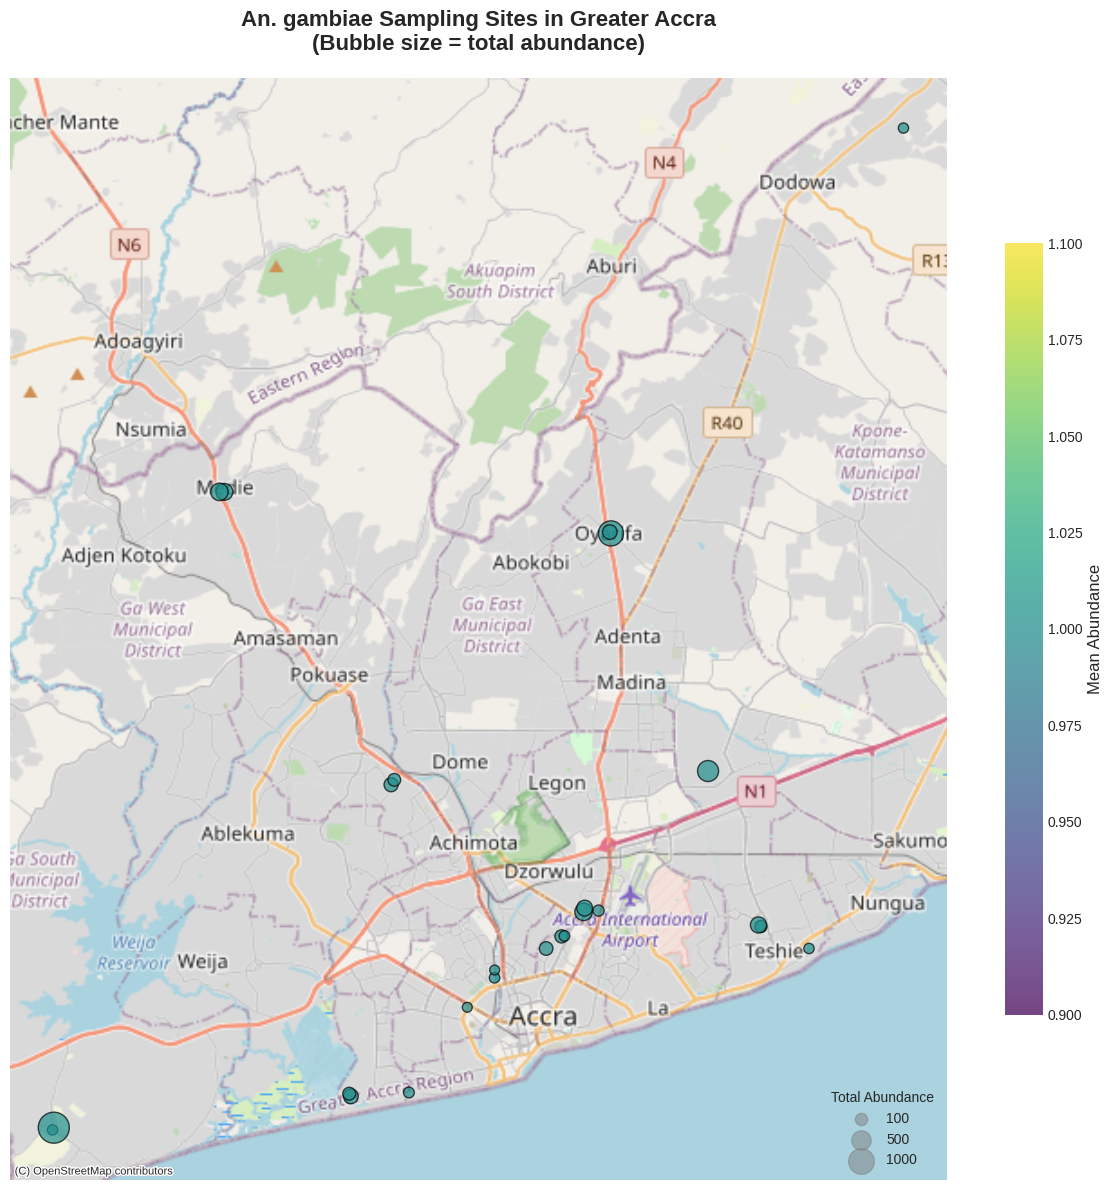

In [12]:
def create_sampling_map(gdf_points, region_name):
    """Create a map of sampling sites with abundance."""
    
    if gdf_points is None or len(gdf_points) == 0:
        print("No points to map")
        return None
    
    # Aggregate by site
    df_sites = gdf_points.groupby(['location_code', 'lat', 'lon'], as_index=False)['count'].agg(['sum', 'mean', 'count'])
    df_sites.columns = ['location_code', 'lat', 'lon', 'total_abundance', 'mean_abundance', 'n_observations']
    
    gdf_sites = gpd.GeoDataFrame(
        df_sites,
        geometry=gpd.points_from_xy(df_sites['lon'], df_sites['lat']),
        crs='EPSG:4326'
    )
    
    # Convert to Web Mercator for basemap
    gdf_sites_3857 = gdf_sites.to_crs(epsg=3857)
    
    # Create map
    fig, ax = plt.subplots(figsize=(12, 12))
    
    # Scale bubble sizes
    min_size = 50
    max_size = 500
    if df_sites['total_abundance'].max() > 0:
        sizes = min_size + (gdf_sites_3857['total_abundance'] / gdf_sites_3857['total_abundance'].max()) * (max_size - min_size)
    else:
        sizes = min_size
    
    # Plot sites
    scatter = ax.scatter(
        gdf_sites_3857.geometry.x,
        gdf_sites_3857.geometry.y,
        s=sizes,
        c=gdf_sites_3857['mean_abundance'],
        cmap='viridis',
        alpha=0.7,
        edgecolors='black',
        linewidth=1
    )
    
    # Add colorbar
    cbar = plt.colorbar(scatter, ax=ax, shrink=0.7)
    cbar.set_label('Mean Abundance', fontsize=12)
    
    # Add basemap
    ctx.add_basemap(ax, source=ctx.providers.OpenStreetMap.Mapnik)
    
    # Add title
    map_title = f'An. gambiae Sampling Sites in {region_name if region_name else COUNTRY_NAME}'
    ax.set_title(map_title + '\n(Bubble size = total abundance)', 
                 fontsize=16, fontweight='bold', pad=20)
    ax.set_axis_off()
    
    # Add legend for bubble sizes
    if df_sites['total_abundance'].max() > 0:
        legend_elements = []
        for size in [100, 500, 1000, 5000]:
            if size <= df_sites['total_abundance'].max():
                s = min_size + (size / df_sites['total_abundance'].max()) * (max_size - min_size)
                legend_elements.append(plt.scatter([], [], s=s, c='gray', alpha=0.5, label=f'{size}'))
        if legend_elements:
            ax.legend(handles=legend_elements, loc='lower right', title='Total Abundance')
    
    plt.tight_layout()
    plt.show()
    
    return gdf_sites


if gdf_filtered_points is not None and len(gdf_filtered_points) > 0:
    gdf_sites = create_sampling_map(gdf_filtered_points, REGION_NAME)
else:
    print("No data for spatial map")

### 10. Summary Statistics and Interpretation

In [13]:
def generate_summary_stats(df_merged, gdf_sites, corr_matrix, lag_correlations, region_name):
    """Generate comprehensive summary statistics."""
    
    if df_merged.empty:
        print("No data available for summary statistics")
        return
    
    region_title = region_name if region_name else COUNTRY_NAME
    
    print("=" * 60)
    print(f"SUMMARY STATISTICS - {region_title}")
    print("=" * 60)
    
    print(f"\nData Overview:")
    print(f"- Analysis period: {df_merged['date_id'].min()} to {df_merged['date_id'].max()}")
    print(f"- Total sampling months: {len(df_merged)}")
    if gdf_sites is not None:
        print(f"- Total sampling sites: {len(gdf_sites)}")
        print(f"- Total observations: {gdf_sites['n_observations'].sum()}")
    
    print(f"\nVector Abundance:")
    print(f"- Mean monthly abundance: {df_merged['total_count'].mean():.1f} (±{df_merged['total_count'].std():.1f})")
    print(f"- Peak abundance: {df_merged['total_count'].max()} (month: {df_merged.loc[df_merged['total_count'].idxmax(), 'date_id']})")
    print(f"- Lowest abundance: {df_merged['total_count'].min()} (month: {df_merged.loc[df_merged['total_count'].idxmin(), 'date_id']})")
    
    if 'temperature_mean_mean' in df_merged.columns:
        print(f"\nTemperature:")
        print(f"- Mean: {df_merged['temperature_mean_mean'].mean():.1f}°C (±{df_merged['temperature_mean_mean'].std():.1f})")
        if 'temperature_mean_min' in df_merged.columns:
            print(f"- Range: {df_merged['temperature_mean_min'].min():.1f}°C to {df_merged['temperature_mean_max'].max():.1f}°C")
    
    if 'rainfall_total_mean' in df_merged.columns:
        print(f"\nRainfall:")
        print(f"- Mean monthly: {df_merged['rainfall_total_mean'].mean():.1f} mm (±{df_merged['rainfall_total_mean'].std():.1f})")
        if 'rainfall_total_min' in df_merged.columns:
            print(f"- Range: {df_merged['rainfall_total_min'].min():.1f} to {df_merged['rainfall_total_max'].max():.1f} mm")
    
    if corr_matrix is not None:
        print(f"\nCorrelations with Abundance:")
        if 'temperature_mean_mean' in corr_matrix.columns:
            print(f"- Temperature: r = {corr_matrix.loc['total_count', 'temperature_mean_mean']:.3f}")
        if 'rainfall_total_mean' in corr_matrix.columns:
            print(f"- Rainfall: r = {corr_matrix.loc['total_count', 'rainfall_total_mean']:.3f}")
    
    if lag_correlations:
        print(f"\nLagged Correlations:")
        for var_name, corrs in lag_correlations.items():
            for lag, corr in enumerate(corrs, 1):
                print(f"- {var_name.capitalize()} (lag {lag}): r = {corr:.3f}")
    
    if gdf_sites is not None:
        print(f"\nTop 5 Sampling Sites by Abundance:")
        top_sites = gdf_sites.nlargest(5, 'total_abundance')[['location_code', 'total_abundance', 'mean_abundance', 'n_observations']]
        print(top_sites.to_string(index=False))
    
    print("\n" + "=" * 60)


if not df_merged.empty:
    generate_summary_stats(df_merged, 
                          gdf_sites if 'gdf_sites' in locals() else None, 
                          corr_matrix if 'corr_matrix' in locals() else None,
                          lag_correlations if 'lag_correlations' in locals() else {},
                          REGION_NAME)

SUMMARY STATISTICS - Greater Accra

Data Overview:
- Analysis period: 2024-01-01 to 2025-01-01
- Total sampling months: 2
- Total sampling sites: 25
- Total observations: 6156

Vector Abundance:
- Mean monthly abundance: 153.0 (±35.4)
- Peak abundance: 178 (month: 2024-01-01)
- Lowest abundance: 128 (month: 2025-01-01)

Temperature:
- Mean: 29.2°C (±0.1)
- Range: 28.1°C to 30.1°C

Rainfall:
- Mean monthly: 0.5 mm (±0.0)
- Range: 0.0 to 4.8 mm

Correlations with Abundance:
- Temperature: r = 1.000
- Rainfall: r = -1.000

Top 5 Sampling Sites by Abundance:
       location_code  total_abundance  mean_abundance  n_observations
point_5_5139_n0_3873             1536             1.0            1536
point_5_7441_n0_1754              946             1.0             946
point_5_6521_n0_1384              612             1.0             612
point_5_5975_n0_1857              376             1.0             376
point_5_7602_n0_3243              370             1.0             370



### 11. Export Results

In [14]:
def export_results(df_merged, gdf_sites, region_name):
    """Export results to CSV for further analysis."""
    
    if df_merged.empty:
        print("No data to export")
        return
    
    # Create exports directory if it doesn't exist
    export_dir = Path.cwd() / 'exports'
    export_dir.mkdir(exist_ok=True)
    
    region_slug = region_name.lower().replace(' ', '_') if region_name else COUNTRY_NAME.lower().replace(' ', '_')
    
    # Export merged time series
    filename = export_dir / f'monthly_analysis_{region_slug}.csv'
    df_merged.to_csv(filename, index=False)
    print(f"Exported monthly analysis to: {filename}")
    
    # Export site statistics
    if gdf_sites is not None:
        filename = export_dir / f'site_statistics_{region_slug}.csv'
        site_cols = ['location_code', 'lat', 'lon', 'total_abundance', 'mean_abundance', 'n_observations']
        if all(col in gdf_sites.columns for col in site_cols):
            gdf_sites[site_cols].to_csv(filename, index=False)
            print(f"Exported site statistics to: {filename}")
    
    print("\nAll results exported successfully!")


if not df_merged.empty:
    export_results(df_merged, gdf_sites if 'gdf_sites' in locals() else None, REGION_NAME)

Exported monthly analysis to: /home/void/Documents/codes/vbd-cdm/notebooks/exports/monthly_analysis_greater_accra.csv
Exported site statistics to: /home/void/Documents/codes/vbd-cdm/notebooks/exports/site_statistics_greater_accra.csv

All results exported successfully!
